In [1]:
# This import is necessary to run the code cell-by-cell
from lab02_solution import *

In [2]:
op = Lab02_op()
kdata = op.load_kdata()
kdata_os = op.load_kdata_os()

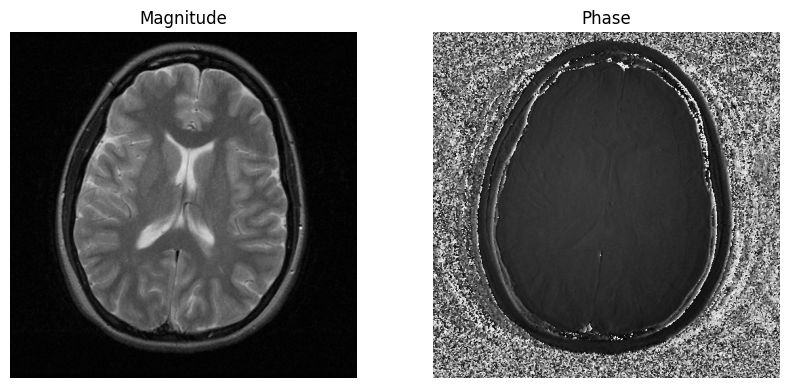

In [ ]:
# Magnitude and Phase of the reconstructed image
reconstructed = op.ifft2c(kdata)
utils.imshow([np.abs(reconstructed), np.angle(reconstructed)], titles=["Magnitude", "Phase"], is_mag=False)

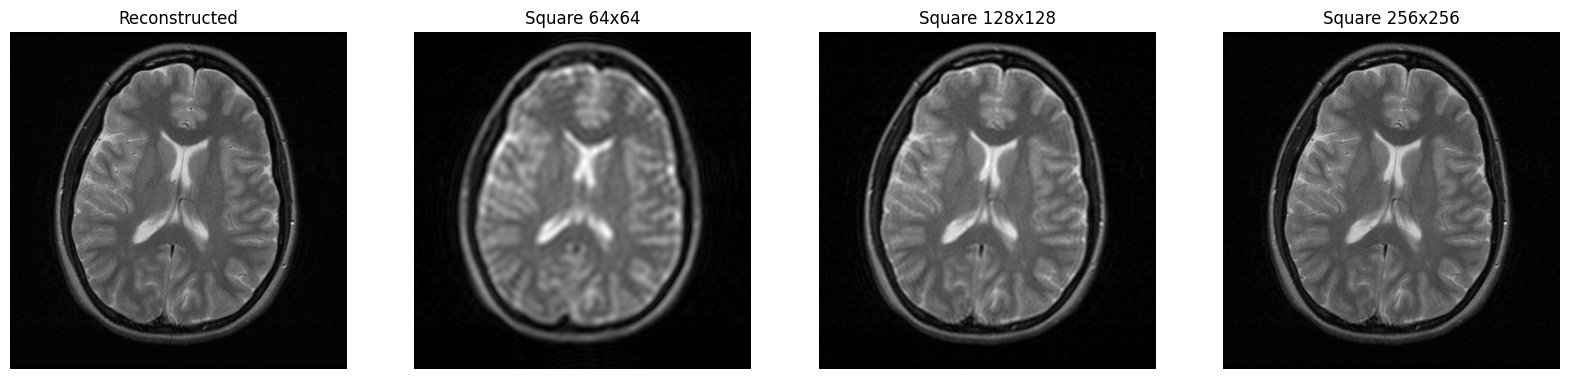

In [ ]:
# Reconstructions of square-filtered k-space
utils.imshow([reconstructed, reconstructed_image_square64, reconstructed_image_square128, reconstructed_image_square256], ["Reconstructed", "Square 64x64", "Square 128x128", "Square 256x256"])


In [ ]:
# point spread function of the square filter
psf_square64 = op.get_psf_1d_square(kdata, mask_size=64)
psf_square128 = op.get_psf_1d_square(kdata, mask_size=128)
psf_square256 = op.get_psf_1d_square(kdata, mask_size=256)

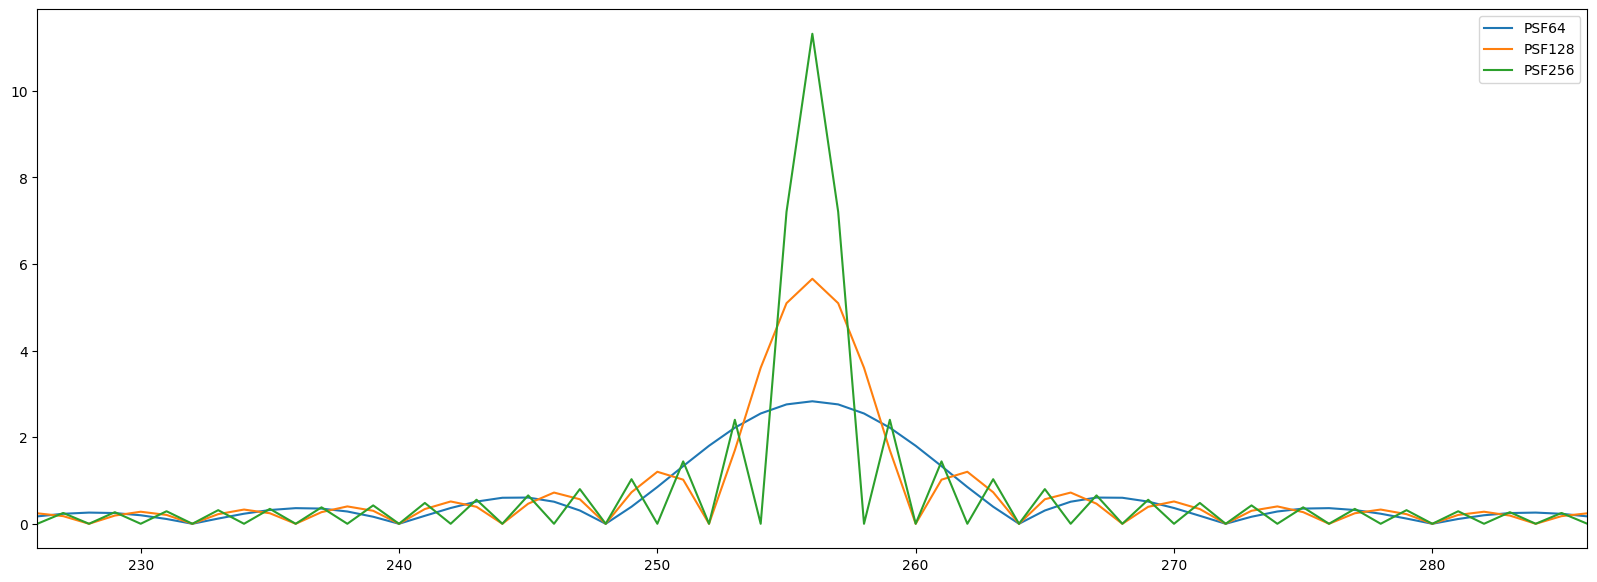

In [9]:
utils.plot([psf_square64, psf_square128, psf_square256], ["PSF64", "PSF128", "PSF256"], xlim=[256-30, 256+30])

In [ ]:
# Compute the full-width at half-maximum (FWHM) for each PSF
fwhm64 = op.get_fwhm(psf_square64)
fwhm128 = op.get_fwhm(psf_square128)
fwhm256 = op.get_fwhm(psf_square256)

print(f"FWHM for 64: {fwhm64:.3f}")
print(f"FWHM for 128: {fwhm128:.3f}")
print(f"FWHM for 256: {fwhm256:.3f}")

FWHM for 64: 10.000
FWHM for 128: 4.000
FWHM for 256: 2.000


In [13]:
reconstructed_image = op.ifft2c(kdata)

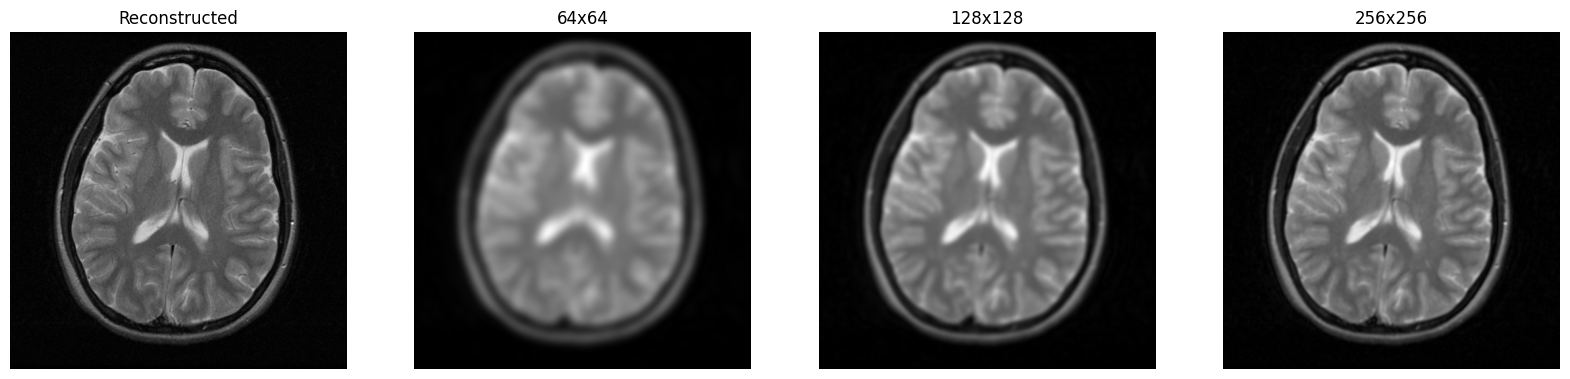

In [14]:
utils.imshow(
    [
        reconstructed_image,
        reconstructed_image_hamming64,
        reconstructed_image_hamming128,
        reconstructed_image_hamming256,
    ],
    ["Reconstructed", "64x64", "128x128", "256x256"]
)

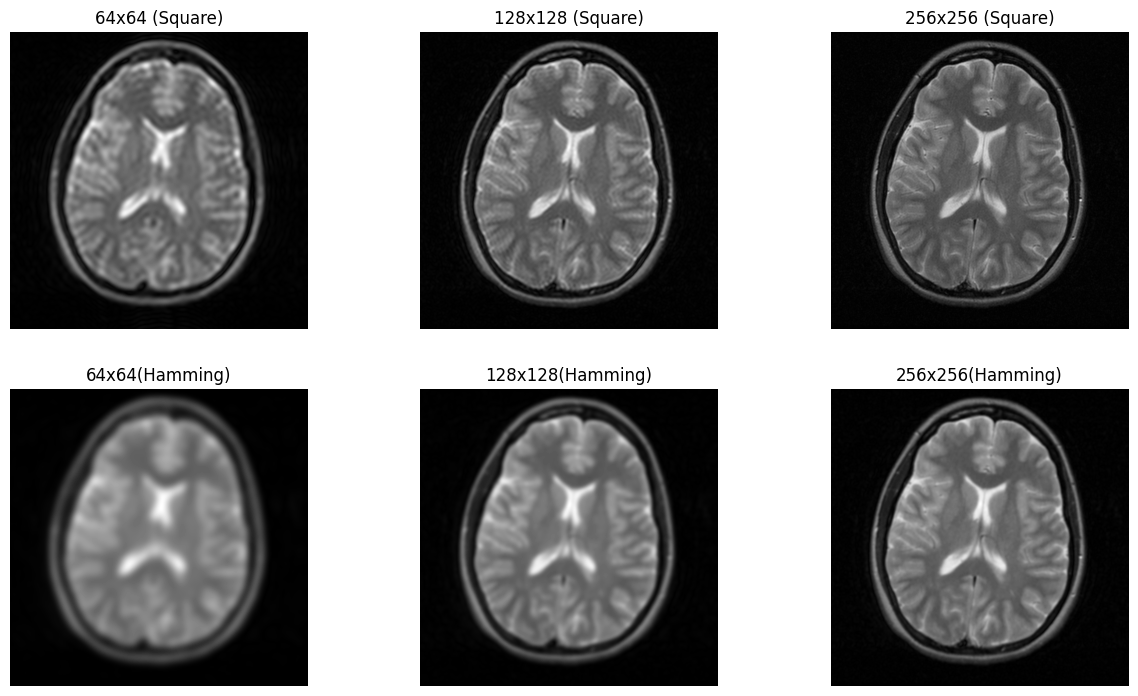

In [15]:
## Compare the results with the square filter
utils.imshow(
    [
        reconstructed_image_square64,
        reconstructed_image_square128,
        reconstructed_image_square256,
        reconstructed_image_hamming64,
        reconstructed_image_hamming128,
        reconstructed_image_hamming256,
    ],
    [
        "64x64 (Square)",
        "128x128 (Square)",
        "256x256 (Square)",
        "64x64(Hamming)",
        "128x128(Hamming)",
        "256x256(Hamming)",
    ],
    num_rows=2,
)

In [16]:
## Define the PSF for Hamming filter of size [64, 128, 256]
# Point spared function (PSF)
psf_hamming64 = op.get_psf_1d_hamming(kdata, 64)
psf_hamming128 = op.get_psf_1d_hamming(kdata, 128)
psf_hamming256 = op.get_psf_1d_hamming(kdata, 256)

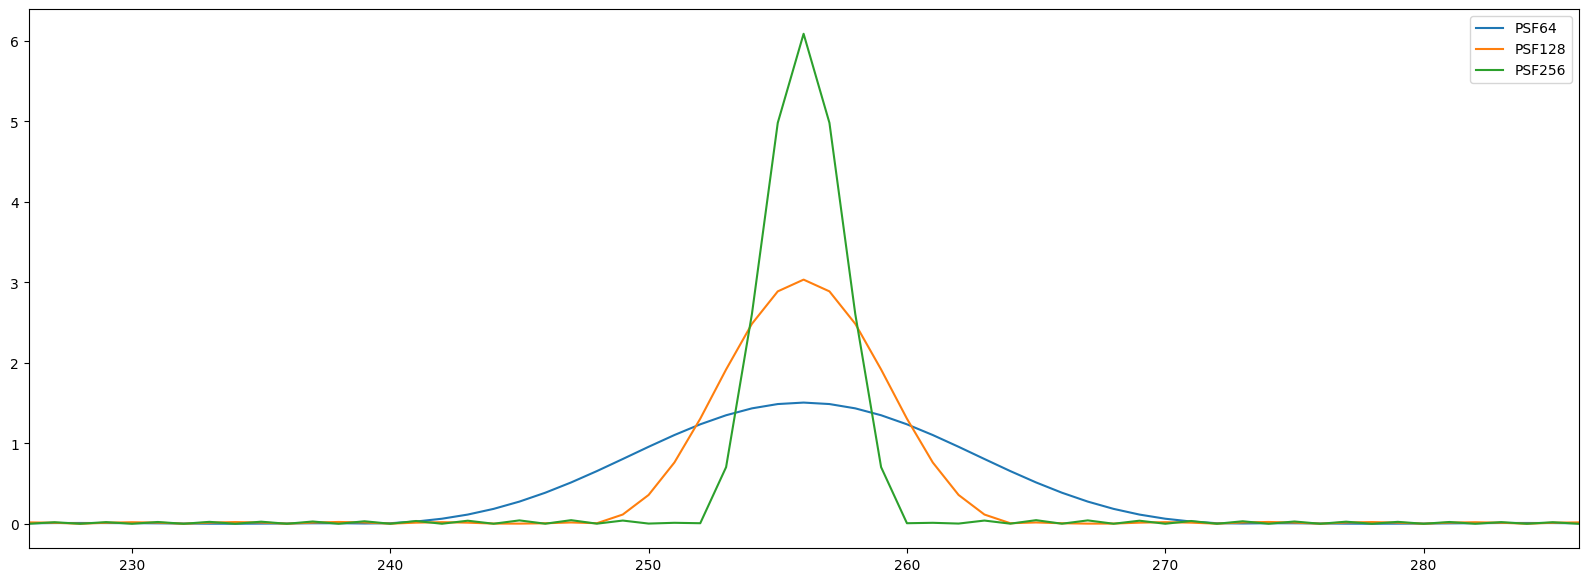

In [17]:
## Display the PSF for hamming filter of size [64, 128, 256]
utils.plot(
    [psf_hamming64, psf_hamming128, psf_hamming256],
    ["PSF64", "PSF128", "PSF256"],
    xlim=[256 - 30, 256 + 30],
)

In [18]:
## Compute the full-width at half-maximum (FWHM) for each PSF
fwhm64 = op.get_fwhm(psf_hamming64)
fwhm128 = op.get_fwhm(psf_hamming128)
fwhm256 = op.get_fwhm(psf_hamming256)

print(f"FWHM for 64: {fwhm64:.3f}")
print(f"FWHM for 128: {fwhm128:.3f}")
print(f"FWHM for 256: {fwhm256:.3f}")

FWHM for 64: 14.000
FWHM for 128: 8.000
FWHM for 256: 4.000


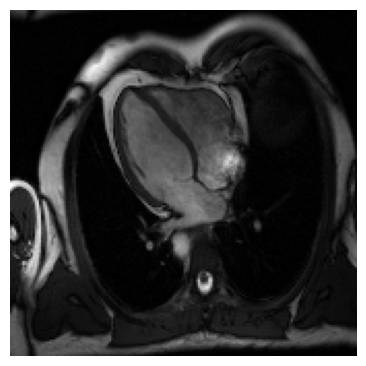

In [19]:
reconstructed_image_os = op.cut_oversampled(kdata_os, 2)
utils.imshow([reconstructed_image_os])